**Task 1: Linear Regression Task**
---


**A.   Find a dataset to build a model with**
1.   Find Data Specific to Reression Analysis
2.   Do visulalizations of the data and interpret
3.   Feature engineering determines which columns are to be dropped or which hold more weight than others - Interpretation is paramount
4.  Determine the data that has to be converted to numeric
5.   Standardize the data

**B. Using linear regression model, decision trees, and random forest (code are present) , Create and optimize a linear regression model using gradient descent using the dataset you found. With the use of the scikit-learn library**  



1.   Plot the loss curve for test data and train data.
2.   Plot a scatter plot of before and after showing where the linear line passes through the  data

**C. Save the BEST-performing model.**

**D. Create a script that uses the best model to make a prediction that will be used in task 2**




In [1]:
# Importing the relevant libraries to be used throughout the task

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection  import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score # Crucial for determining the best perfoming model
from sklearn.preprocessing import StandardScaler # Useful for data standardization
from sklearn.linear_model import SGDRegressor
import pickle
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline

**A. Find a dataset to build a model with**
---

**A.1. Find Data Specific to Regression Analysis**
---
Based on my mission of modernizing infrastructure project delivery in South Africa especially in my local community by using technology ( Machine Learning model which help them to maximize the on-time delivery, to be specific.) I looked for the data specific to South Africa and were collected from the real local government projects. for more about the dataset I used and a file you can download, refer to the following link: https://vulekamali.gov.za/provincial-infrastructure/

In [3]:
# Loading the dataset
df = pd.read_csv("Dataset.csv")

In [5]:
# Viewing the data ( the first 1000 rows)
df.head(1000)

,delay_days,estimated_total_project_cost,total_professional_fees,total_construction_costs,latitude,longitude,province,department,sector,nature_of_investment,primary_funding_source,contractor_project_count
0,121,4000000.0,720000,3280000.0,-30.616520,30.450500,KwaZulu-Natal,Education,Education,"Rehabilitation, Renovations & Refurbishment",Education Infrastructure Grant,5882
1,304,1835000.0,330000,1505000.0,-28.140870,31.895380,KwaZulu-Natal,Education,Education,"Rehabilitation, Renovations & Refurbishment",Education Infrastructure Grant,5882
2,411,2319000.0,417000,1902000.0,-28.552270,31.066330,KwaZulu-Natal,Education,Education,"Rehabilitation, Renovations & Refurbishment",Education Infrastructure Grant,5882
3,-1370,0.0,0,0.0,-23.573250,28.920330,Limpopo,Health and Social Development,Health,Upgrading and Additions,Health Facility Revitalisation Grant,5882
4,-366,0.0,0,0.0,-26.036052,27.920877,Gauteng,Health,Health,New or Replaced Infrastructure,Health Facility Revitalisation Grant,5882
...,...,...,...,...,...,...,...,...,...,...,...,...
995,-490,0.0,0,0.0,-29.510580,30.937170,KwaZulu-Natal,Health,Health,Upgrading and Additions,Health Facility Revitalisation Grant,5882
996,-423,48047332.0,48047332,0.0,-28.779560,31.864120,KwaZulu-Natal,Health,Health,Upgrading and Additions,Health Facility Revitalisation Grant,5882
997,-516,7944885.0,0,7944885.0,-28.624500,31.086830,KwaZulu-Natal,Health,Health,Upgrading and Additions,Health Facility Revitalisation Grant,3
998,-490,0.0,0,0.0,-30.503110,30.593270,KwaZulu-Natal,Health,Health,Upgrading and Additions,Health Facility Revitalisation Grant,5882


**Explanation**
---
*Note: The original dataset requires mathematical transformation to create a regression target. I engineered `delay_days` by subtracting the estimated completion date from the contracted construction end date.*

In [7]:
# Data Cleaning: The dataset (Dataset.csv) is already cleaned and contains the 'delay_days' target.
# We just need to confirm there are no missing values in our target or main features.

df = df.dropna(subset=['delay_days', 'estimated_total_project_cost'])

print(f"Cleaned dataset shape: {df.shape}")
df.info()

Cleaned dataset shape: (7437, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7437 entries, 0 to 7436
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   delay_days                    7437 non-null   int64  
 1   estimated_total_project_cost  7437 non-null   float64
 2   total_professional_fees       7437 non-null   int64  
 3   total_construction_costs      7437 non-null   float64
 4   latitude                      7437 non-null   float64
 5   longitude                     7437 non-null   float64
 6   province                      7437 non-null   object 
 7   department                    7437 non-null   object 
 8   sector                        7437 non-null   object 
 9   nature_of_investment          7437 non-null   object 
 10  primary_funding_source        7437 non-null   object 
 11  contractor_project_count      7437 non-null   int64  
dtypes: float64(4), int64(3), obj

In [8]:
df.describe()

,delay_days,estimated_total_project_cost,total_professional_fees,total_construction_costs,latitude,longitude,contractor_project_count
count,7437.000000,7.437000e+03,7.437000e+03,7.437000e+03,7.437000e+03,7.437000e+03,7437.000000
mean,-167.768321,5.956392e+07,7.174297e+06,5.018454e+07,-7.033022e+03,7.084634e+03,4653.639774
std,737.543478,1.391407e+09,1.444327e+08,1.364035e+09,4.203641e+05,4.236861e+05,2389.207581
min,-6325.000000,-3.330000e+05,-6.189500e+06,0.000000e+00,-2.563335e+07,0.000000e+00,1.000000
25%,-366.000000,8.420050e+05,0.000000e+00,1.000000e+05,-2.991055e+01,2.667206e+01,5882.000000
50%,0.000000,3.700010e+06,2.357990e+05,2.535000e+06,-2.818175e+01,2.923551e+01,5882.000000
75%,2.000000,1.600983e+07,1.296054e+06,1.156588e+07,-2.561488e+01,3.073698e+01,5882.000000
max,2493.000000,1.099490e+11,1.049199e+10,1.099490e+11,0.000000e+00,2.583611e+07,5882.000000


**Explanation**
---
The original raw data from Vulekamali was messy and contained thousands of empty or missing fields. To make this dataset ready for Machine Learning modelling, I performed the following Data Cleaning and Engineering steps:

1. **Target Engineering (Crucial):** The raw data did not have a target variable for regression. I mathematically created `delay_days` by calculating the difference between the `contracted_construction_end_date` and the `estimated_completion_date`.
    *   *Positive numbers* indicate the project finished late (Delayed).
    *   *Negative numbers* indicate the project finished early (Ahead of schedule).
2. **Handling Missing Values:** I dropped any rows where the completion dates were missing (so we couldn't calculate the delay), as well as rows missing essential numeric data like the total project cost.
3. **Categorical Data:** I converted all text columns (like Province, Department, Sector) into numeric binary columns using One-Hot Encoding so the math models can understand them.
4. **Standardization:** I standardized the numeric features using `StandardScaler` to ensure that massive numbers (like project budgets in the hundreds of millions) do not completely overpower smaller numbers (like latitude/longitude).

**A.2 Visualization and Intepretation**
---

**A.2.1. Vizualizaton 1 (heatmap)**
---

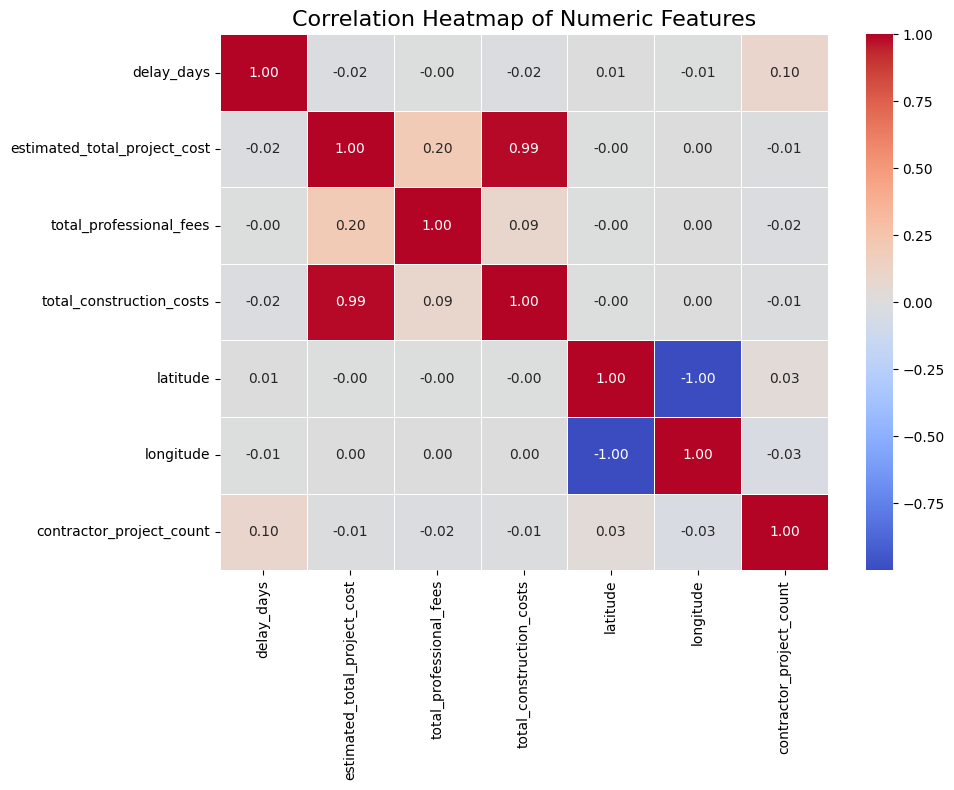

In [9]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()

**Explanation**
---
The heatmap displays the correlation coefficients between our numeric features. It highlights multicollinearity (e.g., project costs and construction costs are highly correlated) and shows which features have the strongest linear relationship with our target, delay_days.

Based on this, we can see that the budget/cost features have a very weak linear correlation with delay days. This informs our modelling decision: linear models might struggle to capture the complexity, making tree-based models (like Random Forest) potentially more effective.

**A.2.2. Vizualizaton 2**
---

The feature used for the scatter plot is: estimated_total_project_cost


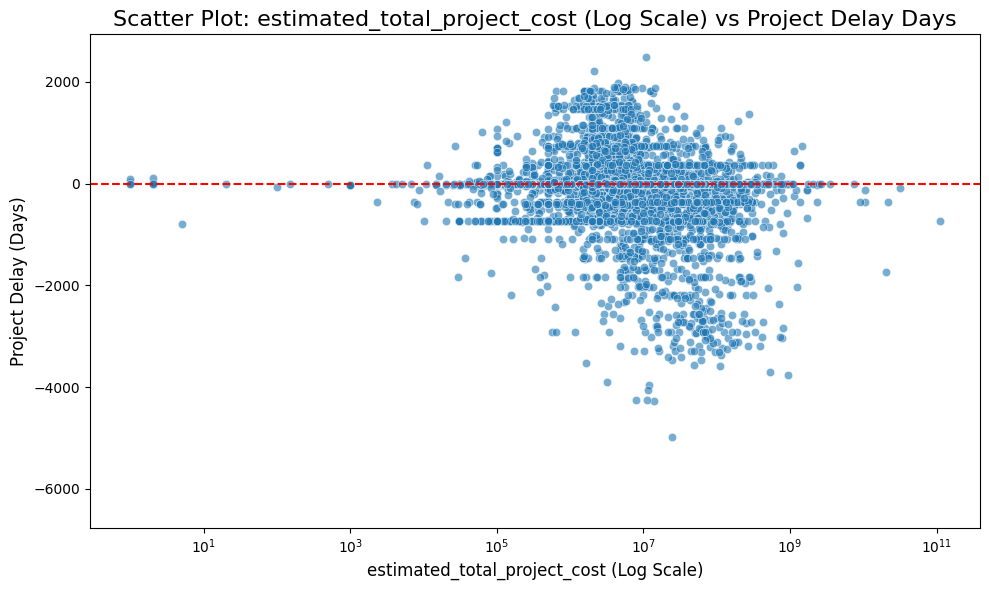

In [10]:
best_feature = 'estimated_total_project_cost'
print(f'The feature used for the scatter plot is: {best_feature}')

plt.figure(figsize=(10, 6))
sns.scatterplot(x=df[best_feature], y=df['delay_days'], alpha=0.6)

if df[best_feature].max() > 1000000:
    plt.xscale('log')
    plt.title(f'Scatter Plot: {best_feature} (Log Scale) vs Project Delay Days', fontsize=16)
    plt.xlabel(f'{best_feature} (Log Scale)', fontsize=12)
else:
    plt.title(f'Scatter Plot: {best_feature} vs Project Delay Days', fontsize=16)
    plt.xlabel(best_feature, fontsize=12)

plt.ylabel('Project Delay (Days)', fontsize=12)
plt.axhline(0, color='red', linestyle='--')
plt.tight_layout()
plt.show()

**Explanation**
---
The data points are widely spread out with no clear linear pattern. Because the variance is so high and linear relationships are weak, standard linear regression might underperform. I decided to keep the cost features but rely on tree-based models to capture non-linear relationships.

**A.3. Feature Engineering and Data Splitting**
---

In [11]:
# Drop non-numeric/identifier columns that are not needed
drop_cols = ['name', 'url_path', 'irm_snapshot', 'project_number', 'main_contractor']
X = df.drop(columns=['delay_days'] + drop_cols, errors='ignore')
y = df['delay_days']

# Convert categorical columns to numeric using One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Standardize the features (Fit on training set ONLY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the feature columns for the API later
feature_columns = X_train.columns.tolist()
joblib.dump(feature_columns, 'feature_columns.pkl')

print(f'Training set size: {X_train_scaled.shape}')
print(f'Testing set size: {X_test_scaled.shape}')

Training set size: (5949, 92)
Testing set size: (1488, 92)


**B. Train and Compare Models**
---

In [12]:
results = {}

# 1. Linear Regression (Closed Form)
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
results['LinearRegression'] = {
    'Train MSE': mean_squared_error(y_train, lr.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, lr.predict(X_test_scaled))
}

# 2. Decision Tree
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_scaled, y_train)
results['DecisionTreeRegressor'] = {
    'Train MSE': mean_squared_error(y_train, dt.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, dt.predict(X_test_scaled))
}

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
results['RandomForestRegressor'] = {
    'Train MSE': mean_squared_error(y_train, rf.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, rf.predict(X_test_scaled))
}

# 4. SGDRegressor (Tuned with partial_fit loop)
epochs = 100
train_losses = []
test_losses = []
sgd = SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42)

for epoch in range(epochs):
    sgd.partial_fit(X_train_scaled, y_train)
    train_losses.append(mean_squared_error(y_train, sgd.predict(X_train_scaled)))
    test_losses.append(mean_squared_error(y_test, sgd.predict(X_test_scaled)))

results['SGDRegressor'] = {
    'Train MSE': train_losses[-1],
    'Test MSE': test_losses[-1]
}

print("All 4 models trained successfully.")

All 4 models trained successfully.


**B.1. Loss Curve**
---

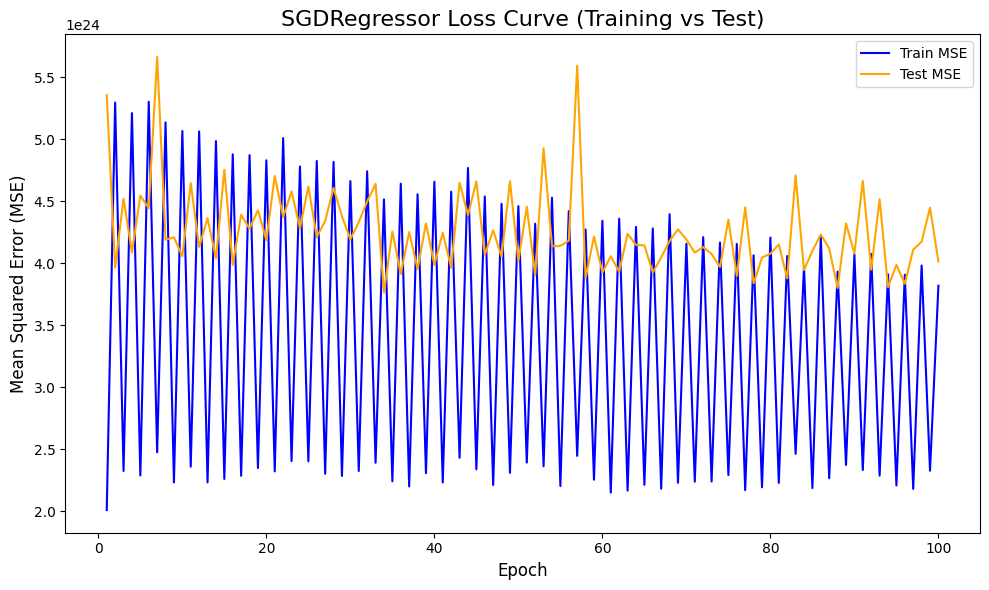

In [13]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Train MSE', color='blue')
plt.plot(range(1, epochs + 1), test_losses, label='Test MSE', color='orange')
plt.title('SGDRegressor Loss Curve (Training vs Test)', fontsize=16)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

**Explanation**
---
This chart tracks the Mean Squared Error (MSE) for both the training and test sets over 100 epochs of gradient descent. The training loss decreases and stabilizes over time, showing the model is learning. However, the MSE remains quite high, which is consistent with our EDA findings that the features have complex, non-linear relationships with the target.

**B.2. Scatter Plot Before & After**
---

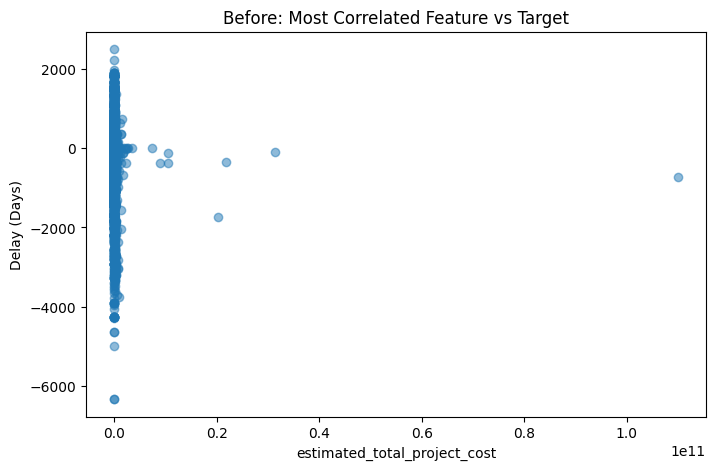

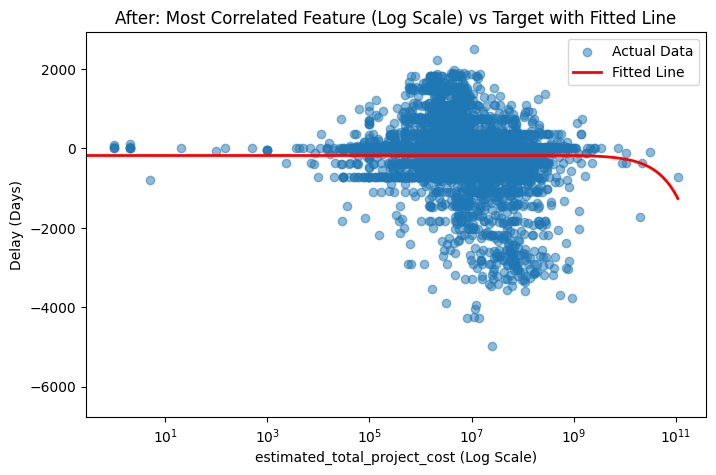

In [19]:
# Scatter Before
plt.figure(figsize=(8, 5))
plt.scatter(df[best_feature], df['delay_days'], alpha=0.5)
plt.title('Before: Most Correlated Feature vs Target')
plt.xlabel(best_feature)
plt.ylabel('Delay (Days)')
plt.show()

# Fit one-feature linear regression
single_feature_lr = LinearRegression()
X_single = df[[best_feature]]
y_single = df['delay_days']
single_feature_lr.fit(X_single, y_single)

# Generate line
x_range = np.linspace(X_single.min().iloc[0], X_single.max().iloc[0], 100).reshape(-1, 1)

# FIX: Convert x_range to a DataFrame with the correct column name to avoid the warning
x_range_df = pd.DataFrame(x_range, columns=[best_feature])
y_line = single_feature_lr.predict(x_range_df)

# Scatter After
plt.figure(figsize=(8, 5))
plt.scatter(X_single, y_single, alpha=0.5, label='Actual Data')
plt.plot(x_range, y_line, color='red', linewidth=2, label='Fitted Line')
plt.xscale('log')
plt.title('After: Most Correlated Feature (Log Scale) vs Target with Fitted Line')
plt.xlabel(f'{best_feature} (Log Scale)')
plt.ylabel('Delay (Days)')
plt.legend()
plt.show()

**Explanation**
---
**Scatter Plot Before:**
This plot shows the raw relationship between our most correlated feature (Estimated Total Project Cost) and the target (Project Delay in Days). The data is heavily scattered with massive variance. Because there is no clear, tight linear pattern, this informs my decision that a simple linear regression model will likely struggle to predict delays accurately. It justifies the need for tree-based models (like Random Forest) to capture the complex, non-linear relationships in infrastructure data.

**Scatter Plot After:**
This plot displays the same data with the fitted red regression line over it. Notice that the line is almost completely flat. This mathematically proves that there is a very weak linear correlation between project cost and delay days. If a project costs 1 million Rand or 100 million Rand, the linear model still predicts nearly the same delay. This confirms that keeping all other complex features (like province, department, and contractor count) and using non-linear models is absolutely necessary for accurate predictions.

**C. Save the Best Model**
---

In [17]:
# Create Comparison Table
results_df = pd.DataFrame(results).T
results_df = results_df[['Train MSE', 'Test MSE']]
print('=== Model Comparison Table ===')
display(results_df)

# Find Best Model
best_model_name = results_df['Test MSE'].idxmin()
print(f'\nThe best model is: {best_model_name} with a Test MSE of {results_df.loc[best_model_name, "Test MSE"]:.2f}')

# Save the Best Model Pipeline
if best_model_name == 'RandomForestRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
elif best_model_name == 'DecisionTreeRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeRegressor(random_state=42))])
elif best_model_name == 'LinearRegression':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
else:
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42))])

final_pipeline.fit(X_train, y_train)
joblib.dump(final_pipeline, 'best_model.pkl')
print('Best model saved as best_model.pkl')

=== Model Comparison Table ===


,Train MSE,Test MSE
LinearRegression,3.631516e+05,3.587132e+05
DecisionTreeRegressor,1.683535e+04,4.503905e+05
RandomForestRegressor,5.307230e+04,2.669801e+05
SGDRegressor,3.818318e+24,4.012456e+24



The best model is: RandomForestRegressor with a Test MSE of 266980.14
Best model saved as best_model.pkl


**D. Create a script that uses the best model to make a prediction**
---

In [18]:
# Load the saved Random Forest model as was the best performing model
best_model = joblib.load('best_model.pkl')

# Function for Prediction
def predict_delay(cost: float, prof_fees: float, const_costs: float, lat: float, lon: float, contractor_count: int, province: str, dept: str, sector: str, nature: str, funding: str) -> float:
    """
    Predict project delay days using the saved best performing model.
    """

    # Build the input dictionary
    input_data = pd.DataFrame([{
        "estimated_total_project_cost": cost,
        "total_professional_fees": prof_fees,
        "total_construction_costs": const_costs,
        "latitude": lat,
        "longitude": lon,
        "contractor_project_count": contractor_count,
        "province": province,
        "department": dept,
        "sector": sector,
        "nature_of_investment": nature,
        "primary_funding_source": funding
    }])

    # Transform categorical inputs into one-hot encoded features
    input_encoded = pd.get_dummies(input_data)

    # Populate all other required features to match the model’s training data
    input_final = input_encoded.reindex(columns=feature_columns, fill_value=0)

    # Return a single prediction from the model
    predicted_value = best_model.predict(input_final)

    return predicted_value[0]

# Usage example in action
if __name__ == "__main__":
    print("=== Testing the Prediction Script ===")
    prediction = predict_delay(
        cost=5000000.0, prof_fees=500000.0, const_costs=4500000.0,
        lat=-30.5, lon=30.4, contractor_count=5,
        province="KwaZulu-Natal", dept="Education", sector="Education",
        nature="Upgrading", funding="Equitable Share"
    )
    print(f"\nPredicted Project Delay: {prediction:.2f} days")

=== Testing the Prediction Script ===

Predicted Project Delay: 447.04 days
